# Exploratory Data Analysis: Glass, Ionosphere, and Iris Datasets
### Comparative Benchmark Study: Conventional SOM vs. Differential Evolution SOM (DE-SOM)

This notebook provides a complete Exploratory Data Analysis (EDA) of the three benchmark datasets used in the study:
1. **Iris Dataset**: Low-dimensional, balanced morphological measurements ($N=150, d=4, C=3$).
2. **Glass Identification Dataset**: Forensic oxide compositions with severe class imbalance ($N=214, d=9, C=6$).
3. **Ionosphere Dataset**: High-frequency radar returns in a high-dimensional continuous space ($N=351, d=34, C=2$).

For each dataset, we construct:
- **Correlation Matrix Heatmap**: Quantifying pairwise linear relationships.
- **Distributed Scatter Plot Matrix**: Pairwise bivariate distributions with univariate Kernel Density Estimations (KDE) along the diagonal.
- **Multivariate Scatter Plot (PCA Projection)**: Mapping all $d$ dimensions to principal components to inspect class separability and geometric dispersion.



In [ ]:
import os
import sys

# Ensure local libraries and matplotlib configurations are loaded
for p in ['/tmp/pylib', os.path.expanduser('~/.local/lib/python3.14/site-packages')]:
    if os.path.exists(p) and p not in sys.path:
        sys.path.insert(0, p)

os.environ['MPLCONFIGDIR'] = '/tmp/mpl'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Configure visualization aesthetics
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print("Libraries imported successfully!")



Libraries imported successfully!


In [ ]:
def load_somlib_dataset(dat_file, names_file):
    with open(names_file, 'r') as f:
        feat_names = f.readline().strip().split()
    with open(dat_file, 'r') as f:
        dim = int(f.readline().strip())
        lines = [line.strip().split() for line in f if line.strip()]
    data = []
    for l in lines:
        row = [float(x) for x in l[:dim]] + [l[dim]]
        data.append(row)
    df = pd.DataFrame(data, columns=feat_names + ['class'])
    return df

df_iris = load_somlib_dataset('iris.dat', 'iris.som.names')
df_glass = load_somlib_dataset('glass.dat', 'glass.som.names')
df_iono = load_somlib_dataset('ionosphere.dat', 'ionosphere.som.names')

# Shorten verbose Glass class labels for cleaner visualization
glass_label_map = {
    'building_windows_float_processed': 'Build Win (Float)',
    'building_windows_non_float_processed': 'Build Win (Non-Float)',
    'vehicle_windows_float_processed': 'Veh Win (Float)',
    'containers': 'Containers',
    'tableware': 'Tableware',
    'headlamps': 'Headlamps'
}
df_glass_clean = df_glass.copy()
df_glass_clean['class_short'] = df_glass_clean['class'].map(glass_label_map)

print(f"Iris loaded: {df_iris.shape}")
print(f"Glass loaded: {df_glass.shape}")
print(f"Ionosphere loaded: {df_iono.shape}")



Iris loaded: (150, 5)
Glass loaded: (214, 10)
Ionosphere loaded: (351, 35)


## 1. Global Class Distribution Comparison
A fundamental characteristic affecting unsupervised clustering and cross-validation is the degree of class balance:
- **Iris**: Perfectly balanced ($50$ per class).
- **Glass**: Highly skewed ($68\%$ building windows vs. only $4.2\%$ tableware).
- **Ionosphere**: Binary classification with moderate class imbalance ($64\%$ good vs. $36\%$ bad).



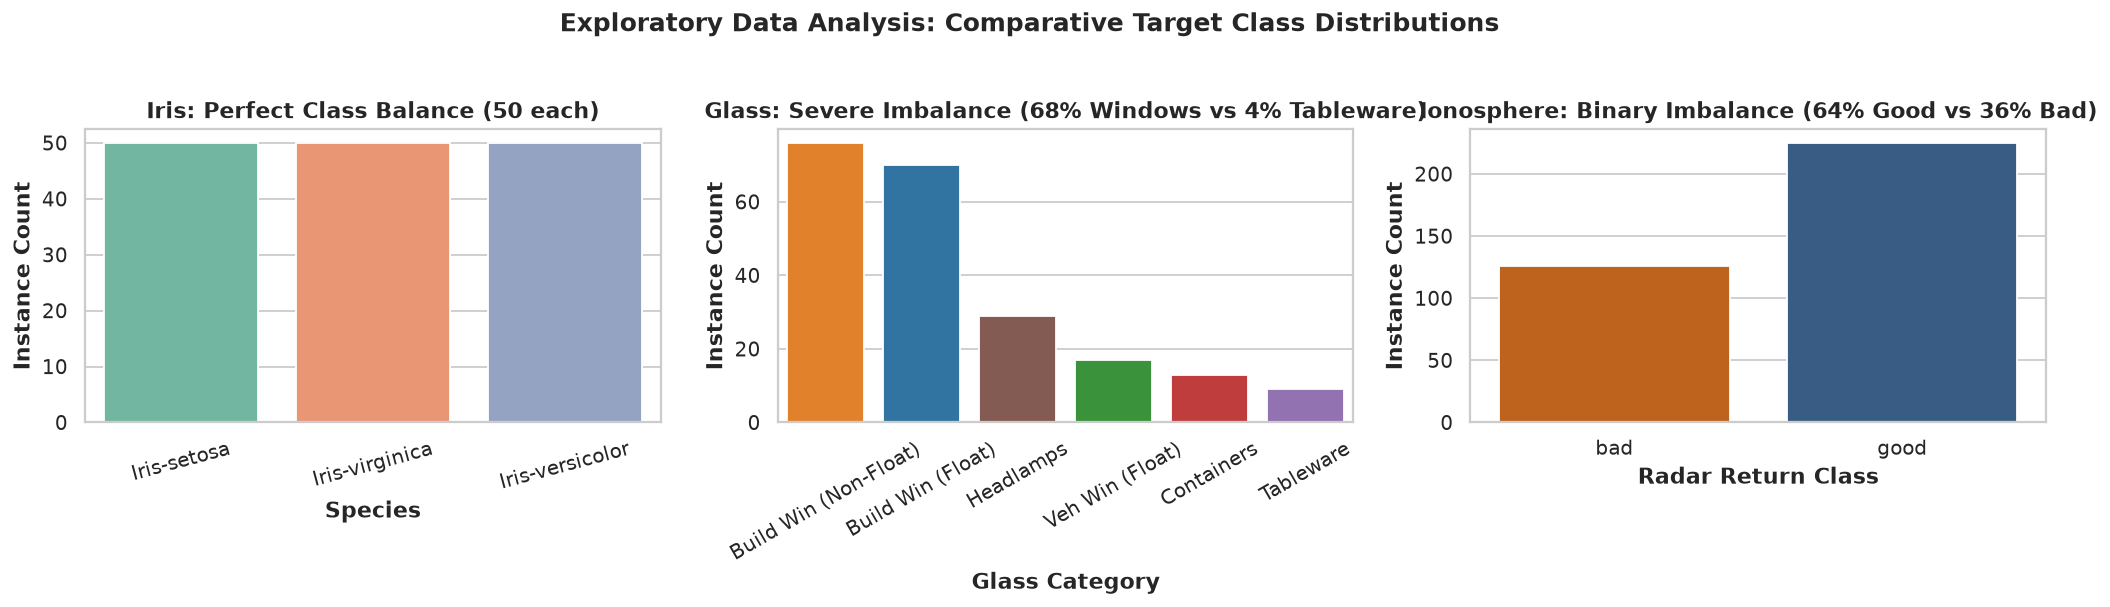

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), dpi=150)

# Iris
sns.countplot(data=df_iris, x='class', hue='class', ax=axes[0], palette='Set2', legend=False)
axes[0].set_title('Iris: Perfect Class Balance (50 each)', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Species', fontweight='semibold')
axes[0].set_ylabel('Instance Count', fontweight='semibold')
axes[0].tick_params(axis='x', rotation=15)

# Glass
sns.countplot(data=df_glass_clean, x='class_short', hue='class_short', ax=axes[1], palette='tab10', legend=False,
              order=['Build Win (Non-Float)', 'Build Win (Float)', 'Headlamps', 'Veh Win (Float)', 'Containers', 'Tableware'])
axes[1].set_title('Glass: Severe Imbalance (68% Windows vs 4% Tableware)', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Glass Category', fontweight='semibold')
axes[1].set_ylabel('Instance Count', fontweight='semibold')
axes[1].tick_params(axis='x', rotation=30)

# Ionosphere
sns.countplot(data=df_iono, x='class', hue='class', ax=axes[2], palette={'good': '#2b5c8f', 'bad': '#d95f02'}, legend=False)
axes[2].set_title('Ionosphere: Binary Imbalance (64% Good vs 36% Bad)', fontweight='bold', fontsize=12)
axes[2].set_xlabel('Radar Return Class', fontweight='semibold')
axes[2].set_ylabel('Instance Count', fontweight='semibold')

plt.suptitle('Exploratory Data Analysis: Comparative Target Class Distributions', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()



---
## 2. Iris Dataset Analysis
The Iris dataset provides a low-dimensional baseline ($N=150, d=4$). With an $8 \times 6$ map ($48$ neurons), DE optimizes a $192$-dimensional vector ($48 \times 4$).

### A. Correlation Matrix Heatmap



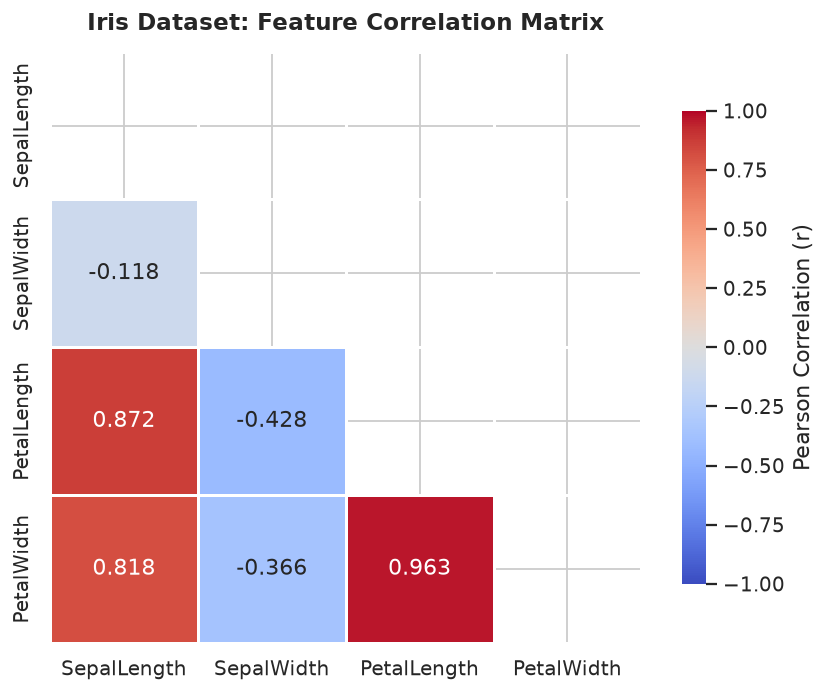

In [ ]:
iris_num = df_iris.drop(columns=['class'])

plt.figure(figsize=(7, 5.5), dpi=150)
mask = np.triu(np.ones_like(iris_num.corr(), dtype=bool))
sns.heatmap(iris_num.corr(), mask=mask, annot=True, fmt='.3f', cmap='coolwarm',
            vmin=-1, vmax=1, square=True, linewidths=1.5, cbar_kws={'shrink': 0.8, 'label': 'Pearson Correlation (r)'})
plt.title('Iris Dataset: Feature Correlation Matrix', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()



### B. Distributed Scatter Plot Matrix
Pairwise scatter plots segmented by species, with marginal Kernel Density Estimation (KDE) curves along the diagonal.



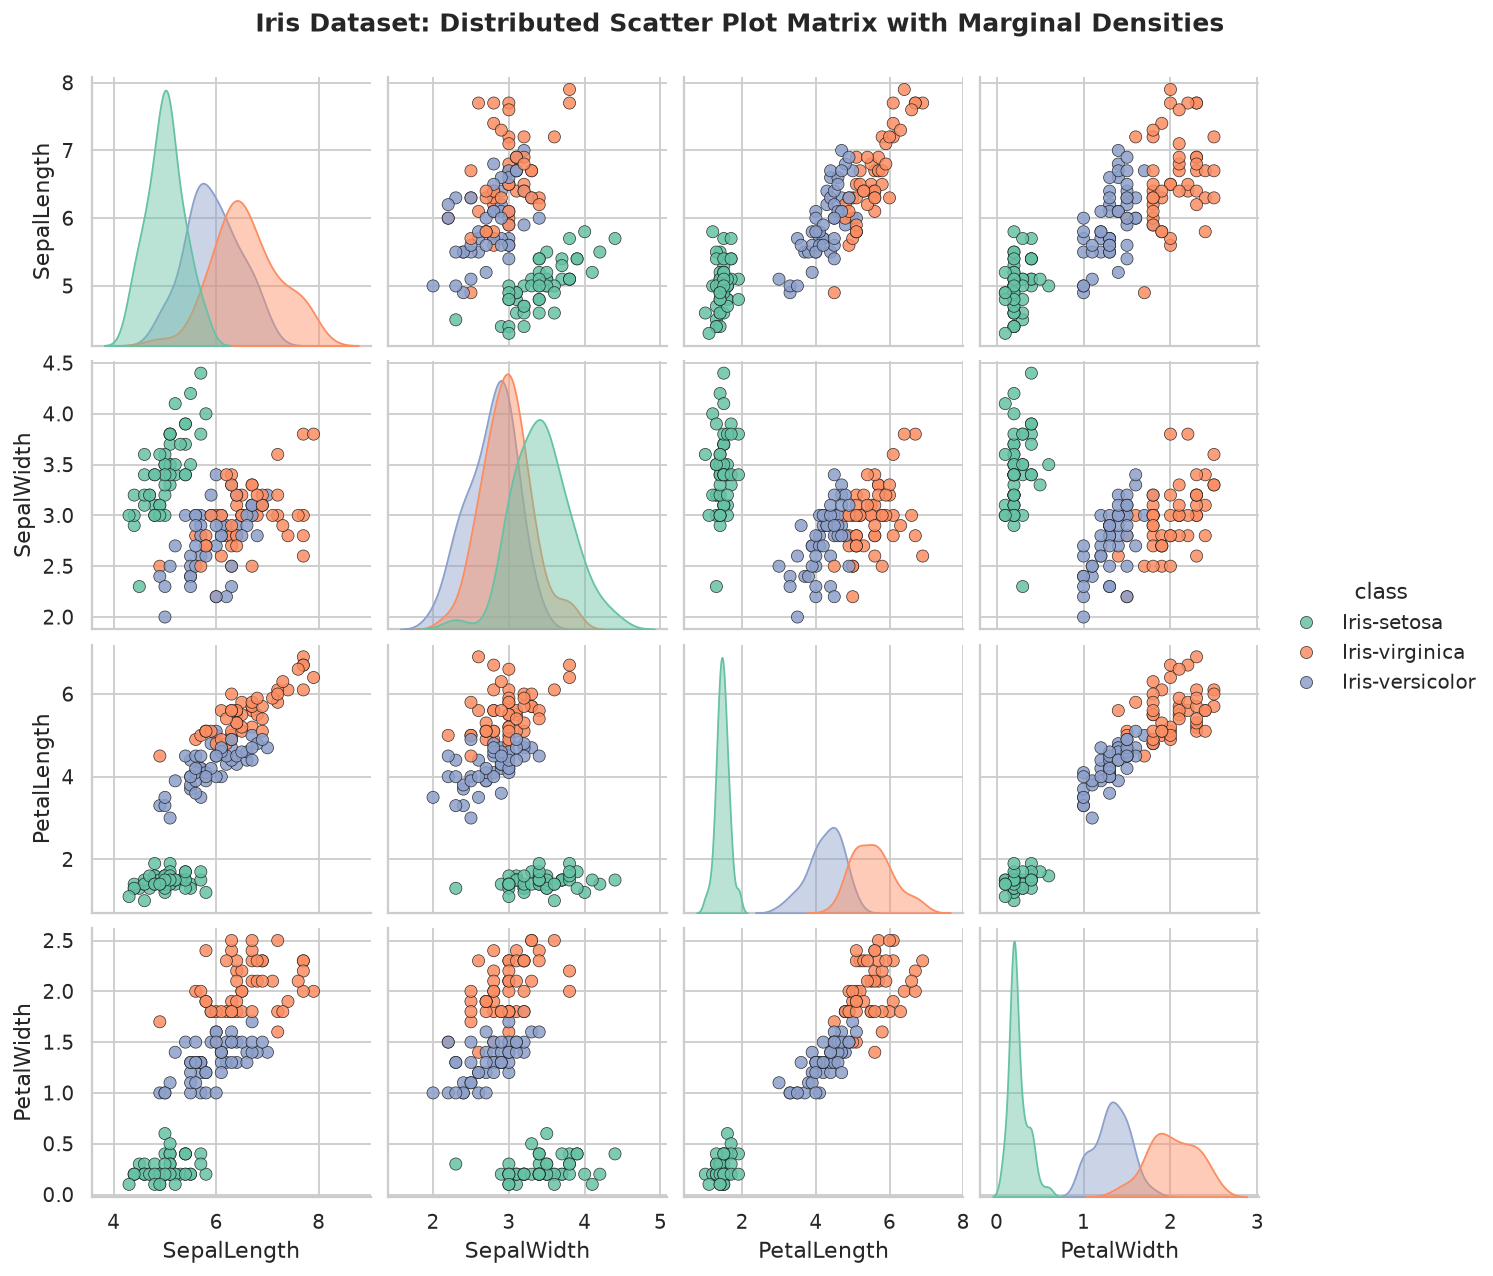

In [ ]:
g_iris = sns.pairplot(df_iris, hue='class', diag_kind='kde', corner=False,
                      palette='Set2', plot_kws={'alpha': 0.85, 's': 45, 'edgecolor': 'k', 'linewidth': 0.4},
                      diag_kws={'fill': True, 'alpha': 0.45})
g_iris.fig.subplots_adjust(top=0.93)
g_iris.fig.suptitle('Iris Dataset: Distributed Scatter Plot Matrix with Marginal Densities', fontsize=14, fontweight='bold')
plt.show()



### C. Multivariate Scatter Plot (PCA 2D Projection)
Principal Component Analysis projects all 4 dimensions into a 2D coordinate system.



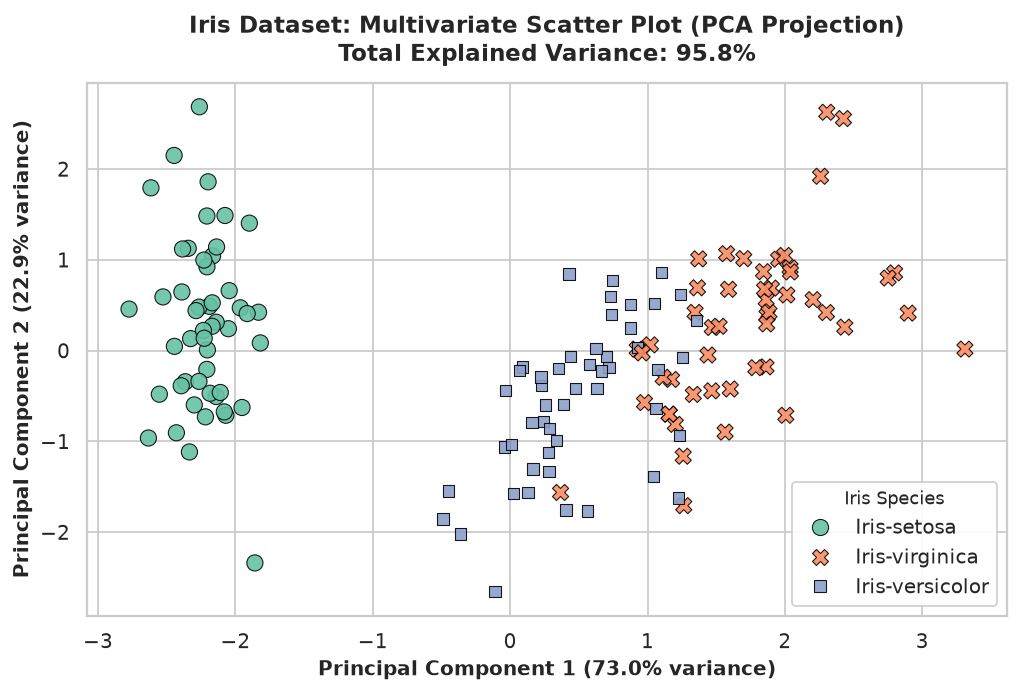

In [ ]:
X_iris_scaled = StandardScaler().fit_transform(iris_num)
pca_iris = PCA(n_components=2)
coords_iris = pca_iris.fit_transform(X_iris_scaled)
df_iris_pca = pd.DataFrame(coords_iris, columns=['PC1', 'PC2'])
df_iris_pca['class'] = df_iris['class']
var_iris = pca_iris.explained_variance_ratio_ * 100

plt.figure(figsize=(8, 5.5), dpi=150)
sns.scatterplot(data=df_iris_pca, x='PC1', y='PC2', hue='class', style='class',
                s=80, alpha=0.9, palette='Set2', edgecolor='black', linewidth=0.6)
plt.title(f'Iris Dataset: Multivariate Scatter Plot (PCA Projection)\nTotal Explained Variance: {var_iris.sum():.1f}%',
          fontsize=13, fontweight='bold', pad=12)
plt.xlabel(f'Principal Component 1 ({var_iris[0]:.1f}% variance)', fontsize=11, fontweight='semibold')
plt.ylabel(f'Principal Component 2 ({var_iris[1]:.1f}% variance)', fontsize=11, fontweight='semibold')
plt.legend(title='Iris Species', title_fontsize=10, frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()



---
## 3. Glass Identification Dataset Analysis
The Glass dataset ($N=214, d=9$) models chemical oxide compositions across 6 glass types. With an $8 \times 6$ map ($48$ neurons), the DE search space is $D = 48 \times 9 = 432$ dimensions.

### A. Correlation Matrix Heatmap (9 Chemical / Physical Oxides)



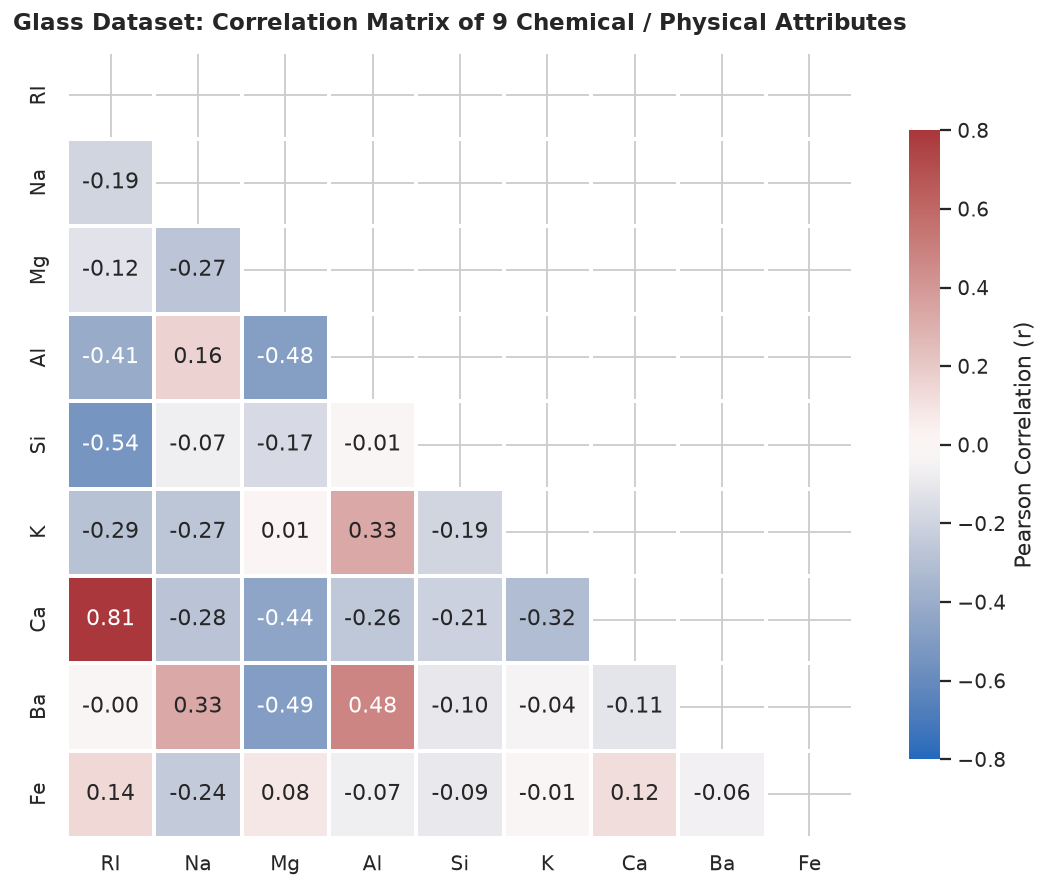

In [ ]:
glass_num = df_glass.drop(columns=['class'])

plt.figure(figsize=(9, 7), dpi=150)
mask_glass = np.triu(np.ones_like(glass_num.corr(), dtype=bool))
sns.heatmap(glass_num.corr(), mask=mask_glass, annot=True, fmt='.2f', cmap='vlag',
            vmin=-0.8, vmax=0.8, square=True, linewidths=1.2,
            cbar_kws={'shrink': 0.8, 'label': 'Pearson Correlation (r)'})
plt.title('Glass Dataset: Correlation Matrix of 9 Chemical / Physical Attributes', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()



### B. Distributed Scatter Plot Matrix (Key Discriminant Oxides)
Pairwise distribution across key discriminating elements: Refractive Index (RI), Sodium (Na), Magnesium (Mg), Aluminum (Al), and Calcium (Ca).



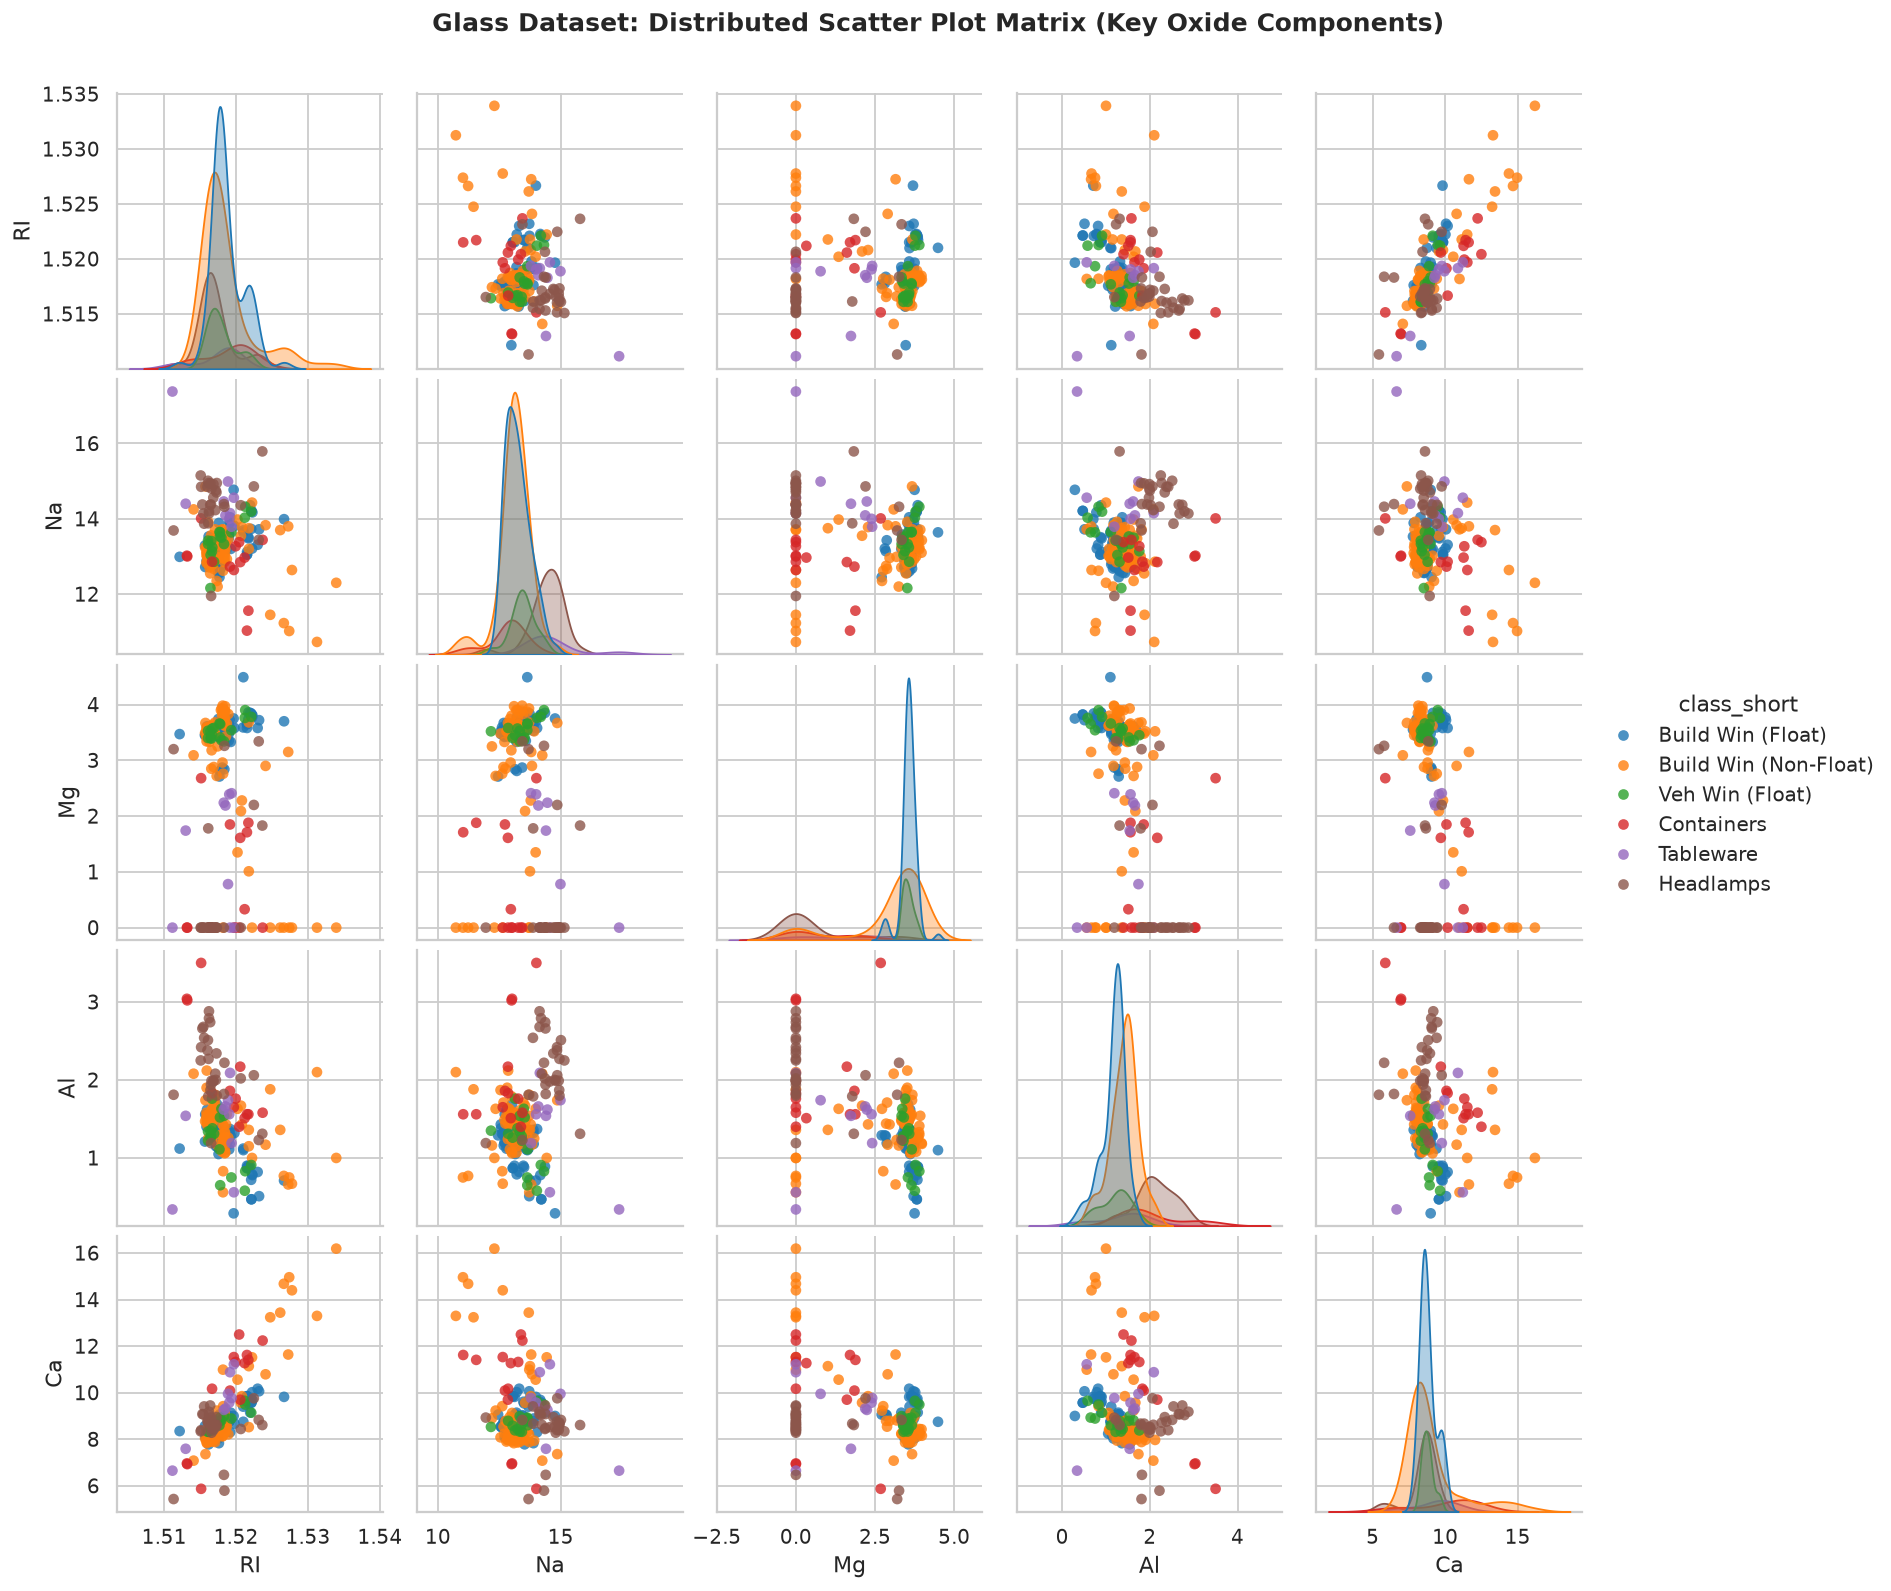

In [ ]:
key_glass_features = ['RI', 'Na', 'Mg', 'Al', 'Ca']
g_glass = sns.pairplot(df_glass_clean[key_glass_features + ['class_short']], hue='class_short',
                       diag_kind='kde', palette='tab10',
                       plot_kws={'alpha': 0.8, 's': 35, 'edgecolor': 'none'},
                       diag_kws={'fill': True, 'alpha': 0.35})
g_glass.fig.subplots_adjust(top=0.93)
g_glass.fig.suptitle('Glass Dataset: Distributed Scatter Plot Matrix (Key Oxide Components)', fontsize=14, fontweight='bold')
plt.show()



### C. Multivariate Scatter Plot (PCA Projection of 9 Features)



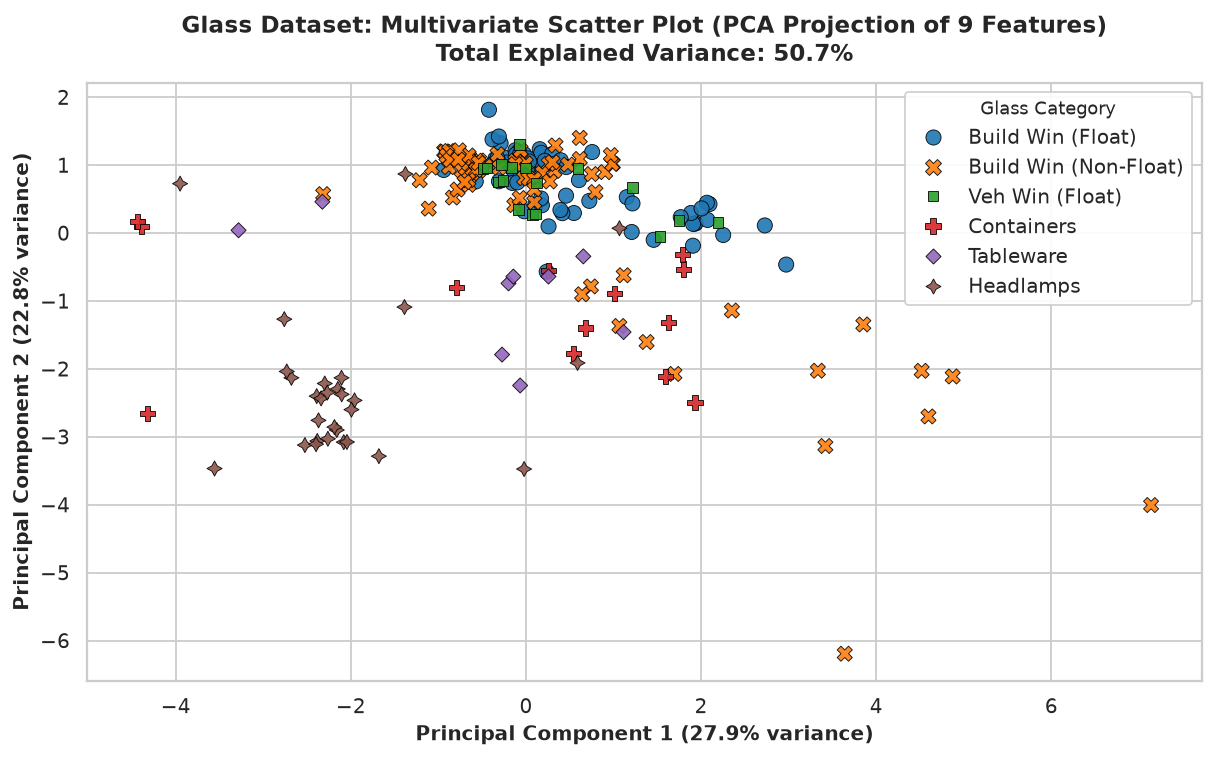

In [ ]:
X_glass_scaled = StandardScaler().fit_transform(glass_num)
pca_glass = PCA(n_components=2)
coords_glass = pca_glass.fit_transform(X_glass_scaled)
df_glass_pca = pd.DataFrame(coords_glass, columns=['PC1', 'PC2'])
df_glass_pca['class_short'] = df_glass_clean['class_short']
var_glass = pca_glass.explained_variance_ratio_ * 100

plt.figure(figsize=(9.5, 6), dpi=150)
sns.scatterplot(data=df_glass_pca, x='PC1', y='PC2', hue='class_short', style='class_short',
                s=70, alpha=0.9, palette='tab10', edgecolor='black', linewidth=0.5)
plt.title(f'Glass Dataset: Multivariate Scatter Plot (PCA Projection of 9 Features)\nTotal Explained Variance: {var_glass.sum():.1f}%',
          fontsize=13, fontweight='bold', pad=12)
plt.xlabel(f'Principal Component 1 ({var_glass[0]:.1f}% variance)', fontsize=11, fontweight='semibold')
plt.ylabel(f'Principal Component 2 ({var_glass[1]:.1f}% variance)', fontsize=11, fontweight='semibold')
plt.legend(title='Glass Category', title_fontsize=10, frameon=True, facecolor='white', framealpha=0.9, loc='best')
plt.tight_layout()
plt.show()



---
## 4. Ionosphere Dataset Analysis
The Ionosphere dataset ($N=351, d=34$) captures high-frequency electromagnetic radar returns. With an $8 \times 6$ map ($48$ neurons), the DE decision space expands to $D = 48 \times 34 = 1,632$ continuous dimensions.

### A. Correlation Matrix Heatmap (All 34 Radar Attributes)



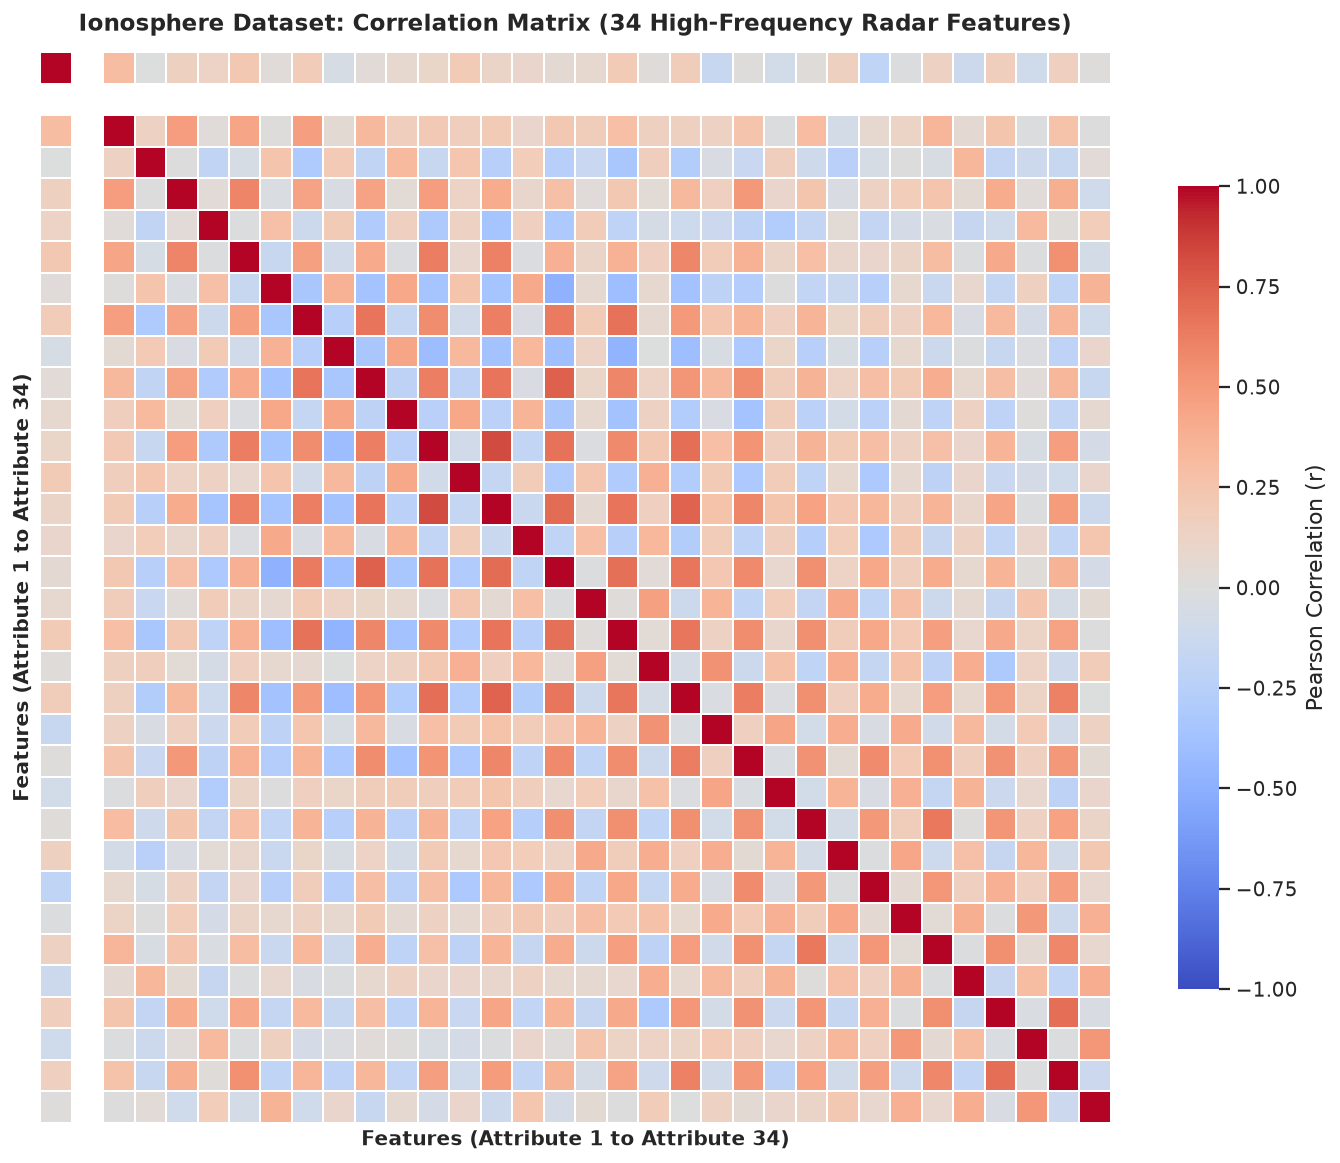

In [ ]:
iono_num = df_iono.drop(columns=['class'])

plt.figure(figsize=(11, 9), dpi=150)
corr_iono = iono_num.corr()
sns.heatmap(corr_iono, cmap='coolwarm', vmin=-1, vmax=1, square=True,
            xticklabels=False, yticklabels=False, linewidths=0.2,
            cbar_kws={'shrink': 0.75, 'label': 'Pearson Correlation (r)'})
plt.title('Ionosphere Dataset: Correlation Matrix (34 High-Frequency Radar Features)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Features (Attribute 1 to Attribute 34)', fontsize=11, fontweight='semibold')
plt.ylabel('Features (Attribute 1 to Attribute 34)', fontsize=11, fontweight='semibold')
plt.tight_layout()
plt.show()



### B. Distributed Scatter Plot Matrix (Selected Radar Return Pulses)
Examining representative pulse components (Attributes 3, 4, 5, 6, and 7) across good vs. bad radar returns.



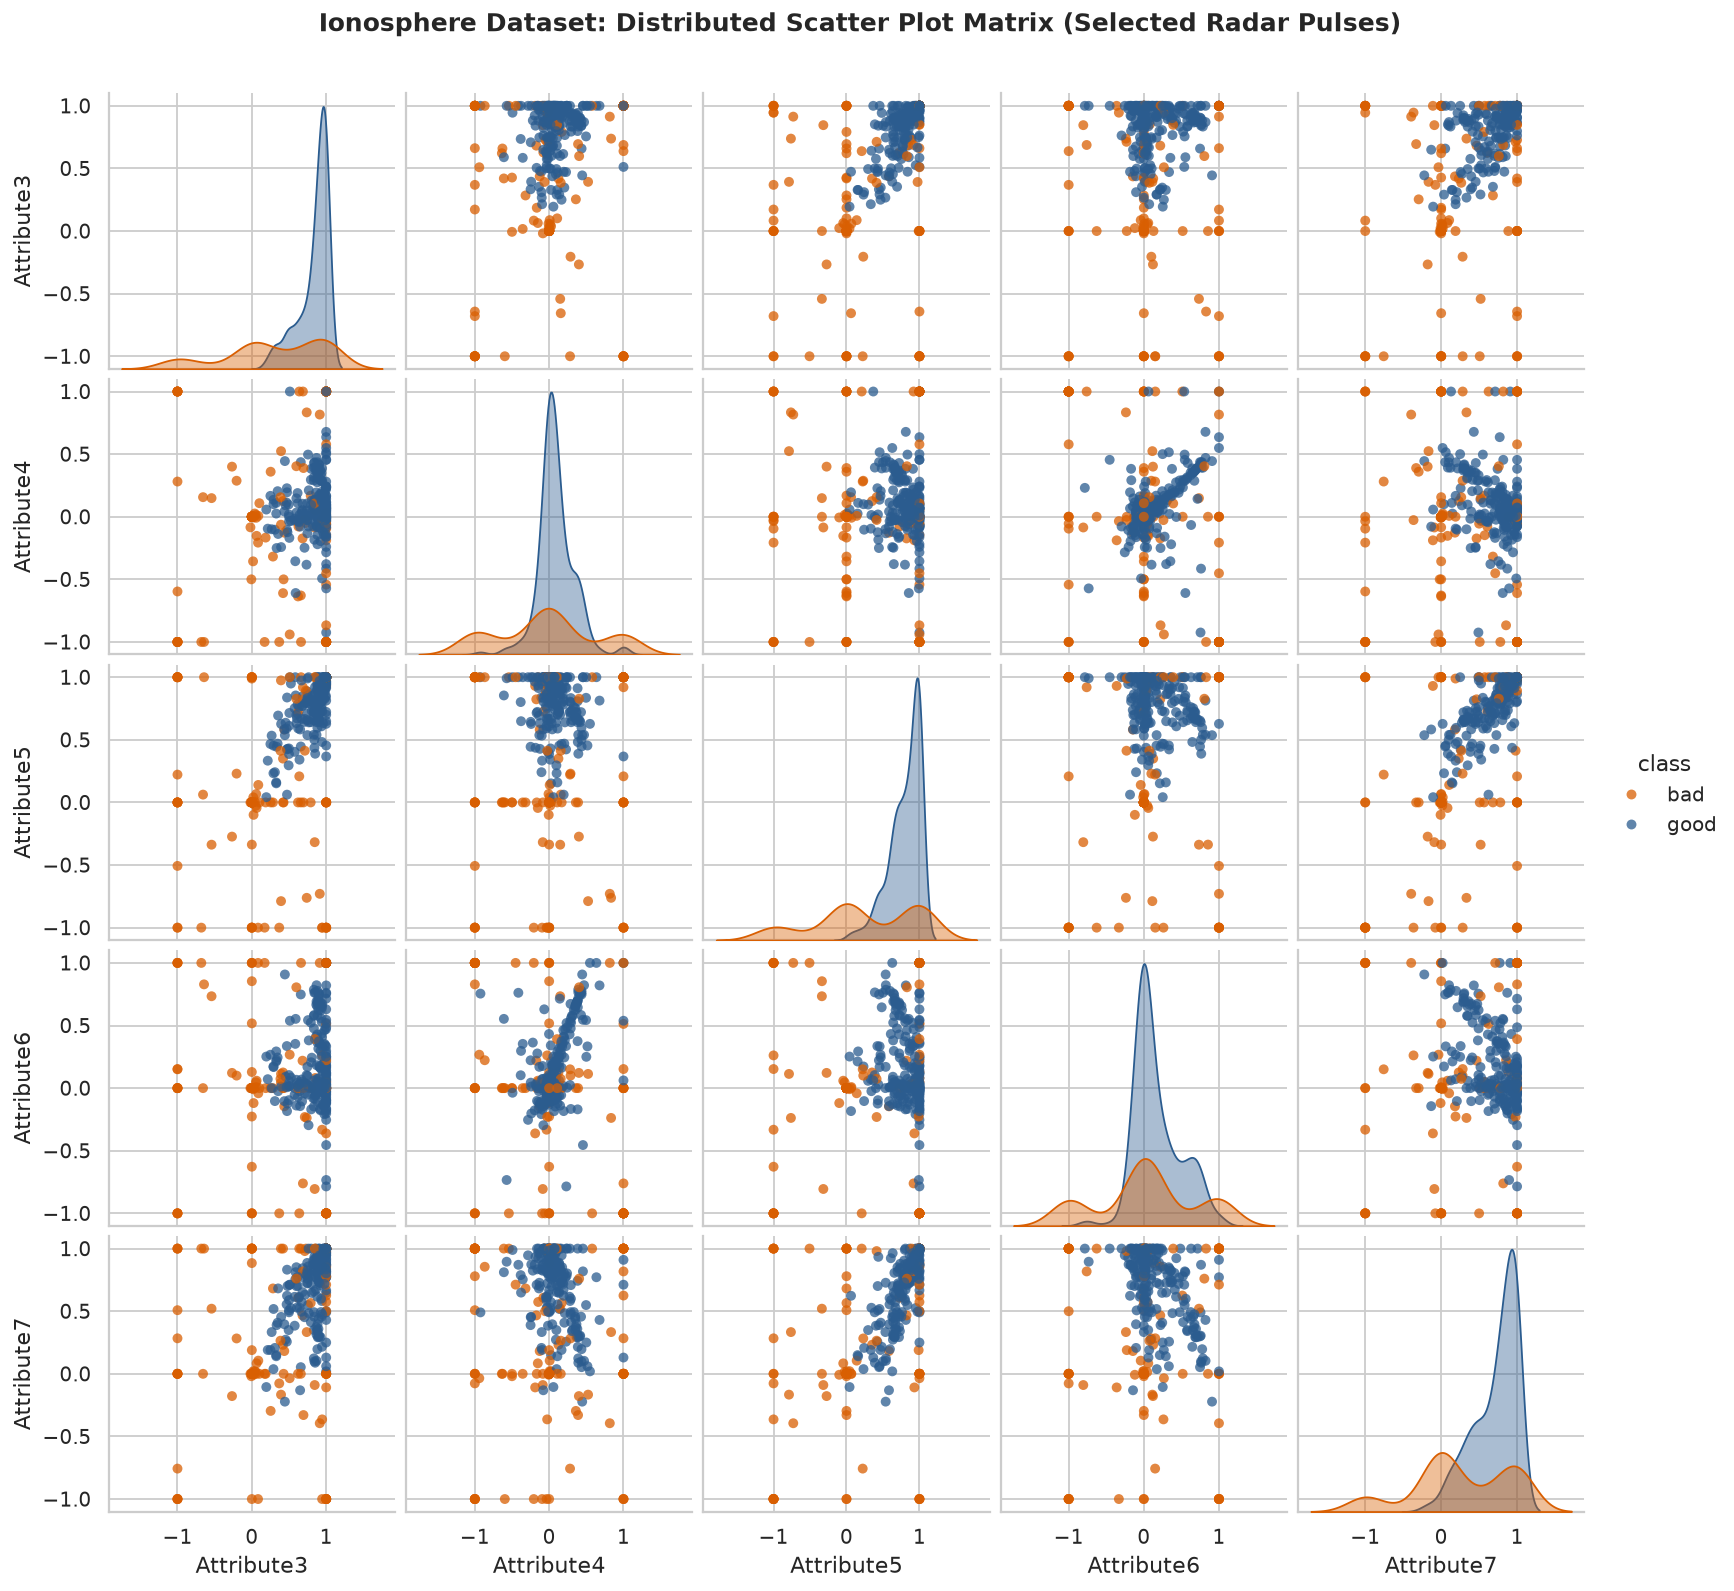

In [ ]:
key_iono_features = ['Attribute3', 'Attribute4', 'Attribute5', 'Attribute6', 'Attribute7']
g_iono = sns.pairplot(df_iono[key_iono_features + ['class']], hue='class', diag_kind='kde',
                      palette={'good': '#2b5c8f', 'bad': '#d95f02'},
                      plot_kws={'alpha': 0.75, 's': 30, 'edgecolor': 'none'},
                      diag_kws={'fill': True, 'alpha': 0.4})
g_iono.fig.subplots_adjust(top=0.93)
g_iono.fig.suptitle('Ionosphere Dataset: Distributed Scatter Plot Matrix (Selected Radar Pulses)', fontsize=14, fontweight='bold')
plt.show()



### C. Multivariate Scatter Plot (PCA Projection of 34 Features)



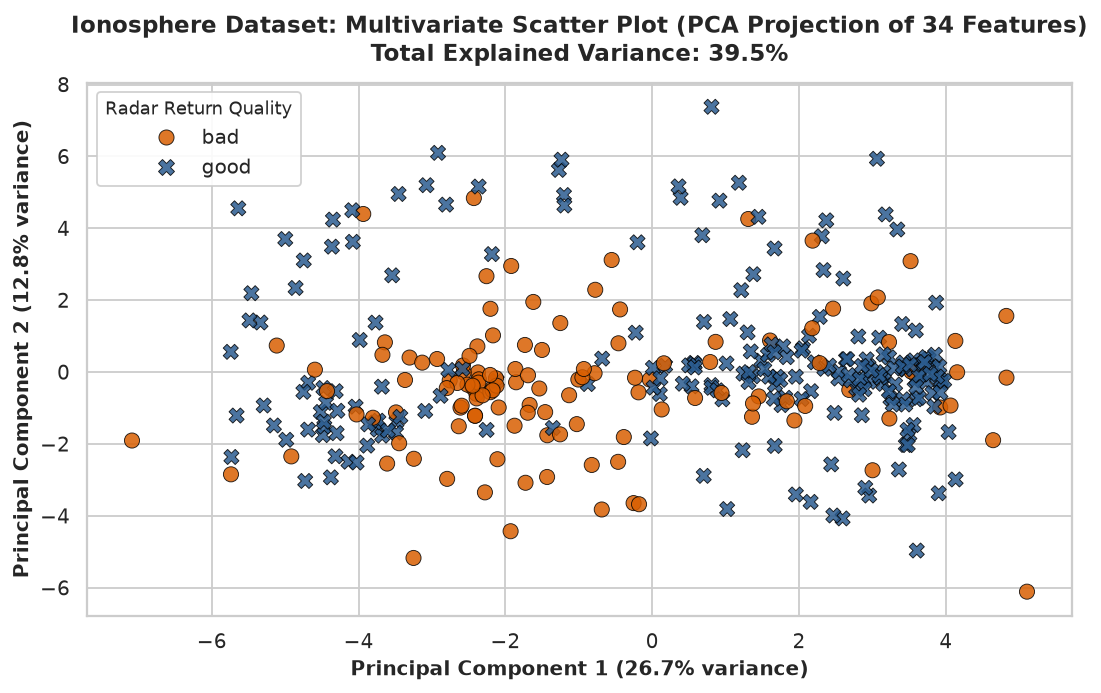

In [ ]:
X_iono_scaled = StandardScaler().fit_transform(iono_num)
pca_iono = PCA(n_components=2)
coords_iono = pca_iono.fit_transform(X_iono_scaled)
df_iono_pca = pd.DataFrame(coords_iono, columns=['PC1', 'PC2'])
df_iono_pca['class'] = df_iono['class']
var_iono = pca_iono.explained_variance_ratio_ * 100

plt.figure(figsize=(8.5, 5.5), dpi=150)
sns.scatterplot(data=df_iono_pca, x='PC1', y='PC2', hue='class', style='class',
                s=70, alpha=0.85, palette={'good': '#2b5c8f', 'bad': '#d95f02'},
                edgecolor='black', linewidth=0.5)
plt.title(f'Ionosphere Dataset: Multivariate Scatter Plot (PCA Projection of 34 Features)\nTotal Explained Variance: {var_iono.sum():.1f}%',
          fontsize=13, fontweight='bold', pad=12)
plt.xlabel(f'Principal Component 1 ({var_iono[0]:.1f}% variance)', fontsize=11, fontweight='semibold')
plt.ylabel(f'Principal Component 2 ({var_iono[1]:.1f}% variance)', fontsize=11, fontweight='semibold')
plt.legend(title='Radar Return Quality', title_fontsize=10, frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()



---
## 5. Synthesis: Linking EDA to Algorithmic Performance

### 1. Feature Scale Disparity and In-Memory Min-Max Normalization (Glass)
- **EDA Finding**: Silicon ($\\approx 72\\%$) and Sodium ($\\approx 13\\%$) dominate the physical scale, whereas trace oxides like Iron ($< 0.1\\%$) and Refractive Index ($1.51 - 1.53$) have tiny ranges.
- **Algorithm Impact**: Without dynamic $[0.0, 1.0]$ normalization, Euclidean distance is monopolized by Silicon, ignoring the remaining 7 forensic attributes. Dynamic in-memory normalization ensures all attributes contribute proportionally.

### 2. High Dimensionality and Evolutionary Search Stagnation (Ionosphere)
- **EDA Finding**: Ionosphere has 34 continuous radar dimensions.
- **Algorithm Impact**: For an $8 \\times 6$ map ($48$ neurons), DE is forced to optimize a $1,632$-dimensional continuous decision space ($48 \\times 34$). The curse of dimensionality severely challenges population-based search ($NP=20$), requiring $4,000$ generations and incurring an $\\approx 62$-minute runtime compared to only $8$ seconds for Conventional SOM.

### 3. The Topographic Error Discrepancy Across All Datasets
- **EDA Finding**: Clusters across all three datasets possess non-linear, multi-modal boundaries in high dimensions.
- **Algorithm Impact**: Conventional SOM enforces topological preservation via its spatial neighborhood kernel $h_{ci}(t)$, achieving $\\text{TE} \\approx 0.06 - 0.13$. DE-SOM minimizes purely Quantization Error without topological penalties, effectively scattering neurons like independent $K$-means centroids and producing severe lattice folding ($\\text{TE} \\approx 0.86 - 0.94$).

